# U.S. Retail Sales Forecasting Using Time-Series Analysis

## Project Overview

This project examines monthly U.S. retail sales from January 1992 through June 2021 and uses a Seasonal Autoregressive Integrated Moving Average (SARIMA) model to forecast the final 12 observed months. The analysis combines historical trend exploration, chronological train/test validation, model diagnostics, and a direct comparison of forecasts with actual sales.

**Business objective:** Evaluate how well a seasonal time-series model forecasts retail sales and identify where forecast errors could affect planning, budgeting, and inventory decisions.

**Analytical questions:** What patterns appear in historical retail sales? How accurately does SARIMA forecast July 2020–June 2021? Where do the largest forecast errors occur, and what do they suggest about the model's usefulness?

## 1. Import Libraries

In [1]:
from pathlib import Path
from math import sqrt
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)


## 2. Set Project Paths

The notebook reads the original dataset from `data/` and saves generated charts and evaluation tables in `figures/` and `results/`. The paths support execution from either the project root or the `notebooks/` folder.

In [2]:
CURRENT_DIR = Path.cwd()

# Support running from either the project root or the notebooks folder.
if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

DATA_DIR = PROJECT_DIR / "data"
FIGURES_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = DATA_DIR / "us_retail_sales.csv"

print("Project folders ready:")
print(" - data/")
print(" - figures/")
print(" - results/")


Project folders ready:
 - data/
 - figures/
 - results/


## 3. Load and Prepare the Dataset

The source CSV stores one year per row, with separate columns for January through December. The preparation process reshapes those month columns into a single date-indexed sales series, sorts the dates, converts values to numeric form, and excludes months without reported sales.

In [3]:
df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully.
Shape: (30, 13)


,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC
0,1992,146925,147223,146805,148032,149010,149800,150761.0,151067.0,152588.0,153521.0,153583.0,155614.0
1,1993,157555,156266,154752,158979,160605,160127,162816.0,162506.0,163258.0,164685.0,166594.0,168161.0
2,1994,167518,169649,172766,173106,172329,174241,174781.0,177295.0,178787.0,180561.0,180703.0,181524.0
3,1995,182413,179488,181013,181686,183536,186081,185431.0,186806.0,187366.0,186565.0,189055.0,190774.0
4,1996,189135,192266,194029,194744,196205,196136,196187.0,196218.0,198859.0,200509.0,200174.0,201284.0


In [4]:
month_mapping = {
    "JAN": 1,
    "FEB": 2,
    "MAR": 3,
    "APR": 4,
    "MAY": 5,
    "JUN": 6,
    "JUL": 7,
    "AUG": 8,
    "SEP": 9,
    "OCT": 10,
    "NOV": 11,
    "DEC": 12
}

rows = []

for _, row in df.iterrows():
    year = int(row["YEAR"])

    for month_name, month_number in month_mapping.items():
        rows.append(
            [
                pd.Timestamp(
                    year=year,
                    month=month_number,
                    day=1
                ),
                row[month_name]
            ]
        )

series_df = pd.DataFrame(
    rows,
    columns=["Date", "Sales"]
)

series_df = (
    series_df
    .sort_values("Date")
    .set_index("Date")
)

sales = series_df["Sales"].astype(float).dropna()

print("Monthly time series created successfully.")
print("Start date:", sales.index.min().strftime("%Y-%m-%d"))
print("End date:", sales.index.max().strftime("%Y-%m-%d"))
print("Observations:", len(sales))


Monthly time series created successfully.
Start date: 1992-01-01
End date: 2021-06-01
Observations: 354


### Interpretation — Data Preparation

The original dataset contains **30 yearly records and 13 columns** (one year field and 12 monthly fields). Reshaping it creates 360 possible month positions for 1992–2021. Because **July–December 2021 have no reported values**, those six positions are excluded, leaving **354 observed months from January 1992 through June 2021**.

This monthly structure is necessary for chronological analysis and for specifying the model's **12-month seasonal cycle**. Missing future observations are not filled with invented sales values, and the source CSV remains unchanged.

## 4. Explore U.S. Retail Sales Trends

The following line chart plots the complete observed monthly series to examine long-term direction, repeated seasonal movement, and periods when sales departed from earlier patterns.

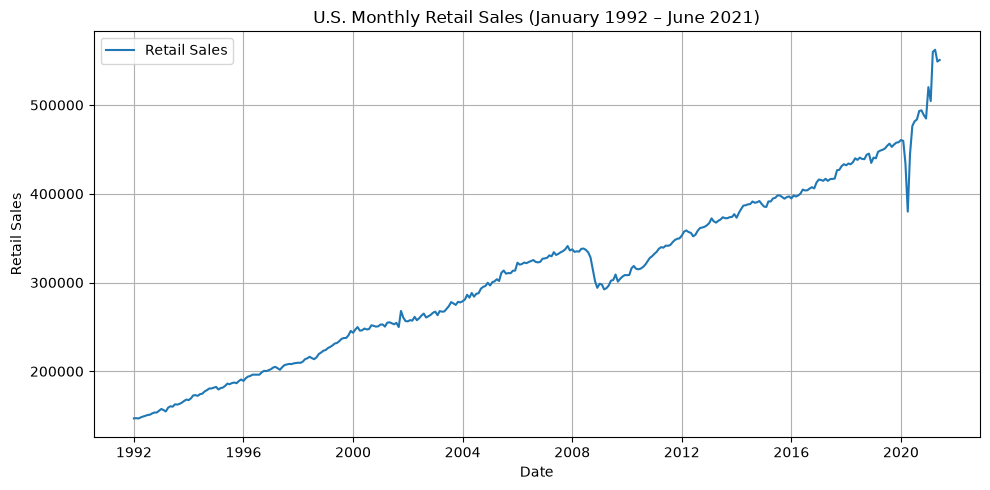

Saved: figures/us_monthly_retail_sales_trend.png


In [5]:
plt.figure(figsize=(10, 5))

plt.plot(
    sales,
    label="Retail Sales"
)

plt.title("U.S. Monthly Retail Sales (January 1992 – June 2021)")
plt.xlabel("Date")
plt.ylabel("Retail Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()

save_path = FIGURES_DIR / "us_monthly_retail_sales_trend.png"
plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figures/us_monthly_retail_sales_trend.png")


### Interpretation — Historical Retail Sales

The chart shows a **substantial long-term increase** in reported monthly retail sales between 1992 and 2021. Repeated within-year fluctuations are visible alongside that broader upward trend, supporting the decision to consider a seasonal forecasting model.

Two periods are especially notable: a decline around the **2008–2009 financial crisis** and a sharp disruption in **2020**, followed by a pronounced rise during **2021**. These shifts matter because a model trained on historical patterns may not anticipate the size or timing of an unusual economic rebound. The chart establishes the historical context for evaluating the forecasts below.

## 5. Create Training and Test Sets

The series is divided **chronologically**, preserving the order in which sales observations occurred. The model is fitted only on the earlier period, and the final 12 observed months are reserved to evaluate forecasts for dates the model did not train on.

In [6]:
sales = sales.sort_index()

train = sales.loc[:"2020-06-01"].copy()
test = sales.loc["2020-07-01":"2021-06-01"].copy()

train.index.freq = "MS"
test.index.freq = "MS"

print(
    "Training period:",
    train.index.min().strftime("%Y-%m-%d"),
    "to",
    train.index.max().strftime("%Y-%m-%d")
)

print(
    "Test period:",
    test.index.min().strftime("%Y-%m-%d"),
    "to",
    test.index.max().strftime("%Y-%m-%d")
)

print("Training size:", len(train))
print("Test size:", len(test))


Training period: 1992-01-01 to 2020-06-01
Test period: 2020-07-01 to 2021-06-01
Training size: 342
Test size: 12


### Interpretation — Chronological Validation

The training set contains **342 months (January 1992–June 2020)**. The test set contains **12 months (July 2020–June 2021)**, representing a full annual cycle. This split allows a meaningful comparison between the model's forecasts and subsequently observed sales while avoiding the look-ahead problem introduced by a random train/test split.

The forecast begins immediately after the training period, so the evaluation tests a **12-step-ahead forecasting exercise** rather than predictions made with access to the test-period sales. Because the training window ends during the 2020 disruption, the test period also provides a demanding assessment of how the model handles a changing retail environment.

## 6. Build the SARIMA Forecasting Model

A **SARIMA(1,1,1)(1,1,1,12)** model is fitted to the training series. The nonseasonal terms describe short-run dependence and differencing, while the seasonal terms account for recurring patterns at a **12-month interval**. The model output reports information criteria and the statistical significance of fitted parameters.

In [7]:
predictive_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

fit = predictive_model.fit(
    disp=False
)

print("SARIMA model fitted successfully.")
print()

print("Model Performance:")
print(f"AIC: {fit.aic:.3f}")
print(f"BIC: {fit.bic:.3f}")
print(f"HQIC: {fit.hqic:.3f}")

print("\nSignificant Parameters:")
display(
    fit.pvalues[
        fit.pvalues < 0.05
    ].to_frame("p_value")
)


SARIMA model fitted successfully.

Model Performance:
AIC: 6430.359
BIC: 6449.122
HQIC: 6437.855

Significant Parameters:


,p_value
ar.L1,2.459697e-11
ma.L1,3.830145e-20
ma.S.L12,3.768812e-04
sigma2,0.000000e+00


### Interpretation — SARIMA Model Diagnostics

The fitted model reports **AIC = 6,430.359**, **BIC = 6,449.122**, and **HQIC = 6,437.855**. These information criteria summarize model fit with complexity penalties; they are most useful when comparing alternative models fitted to the **same training data**. Their values alone do not establish that this specification is the best available or that its forecasts will be accurate.

The output identifies statistically significant coefficients at the **5% level** for the nonseasonal AR(1) and MA(1) terms and the seasonal MA(12) term. This indicates that several modeled temporal relationships contribute to the fitted specification. The next sections assess practical forecasting performance using the held-out 12 months, rather than relying on in-sample diagnostics alone.

## 7. Forecast the Test Period

The fitted model generates **12 monthly forecasts** for July 2020 through June 2021. The table aligns each predicted value with the corresponding observed sales figure so that the size and direction of the errors can be examined month by month.

In [8]:
forecast = fit.forecast(
    steps=len(test)
)

forecast_rounded = forecast.round(1)

forecast_results = pd.DataFrame({
    "Actual": test,
    "Predicted": forecast_rounded
})

display(forecast_results)


,Actual,Predicted
2020-07-01,481627.0,472662.2
2020-08-01,483716.0,469915.8
2020-09-01,493327.0,467295.2
2020-10-01,493991.0,469497.5
2020-11-01,488652.0,470815.3
2020-12-01,484782.0,467042.1
2021-01-01,520162.0,470290.3
2021-02-01,504458.0,469675.9
2021-03-01,559871.0,460669.6
2021-04-01,562269.0,436617.4


In [9]:
forecast_file = RESULTS_DIR / "forecast_results.csv"

forecast_results.to_csv(
    forecast_file,
    index_label="Date"
)

print("Saved: results/forecast_results.csv")


Saved: results/forecast_results.csv


### Interpretation — Monthly Forecast Table

The forecast table provides the detailed evidence behind the comparison chart. During **July–December 2020**, the model's predicted values remain near **467,000–473,000**, while observed values range from approximately **482,000 to 494,000**. In **2021**, the actual series rises above **520,000** in January and reaches **562,269** in April, while the forecasts do not reproduce that increase.

The table also confirms that forecasts are **lower than actual sales for each of the 12 months**. Saving these paired values in `results/forecast_results.csv` makes the evaluation reproducible and allows additional error measures to be calculated later without changing the original dataset.

## 8. Compare Actual and Predicted Retail Sales

The chart plots the 12 held-out actual observations against the forecasts. Comparing the two lines reveals whether the model follows the direction and magnitude of the changes during the evaluation period.

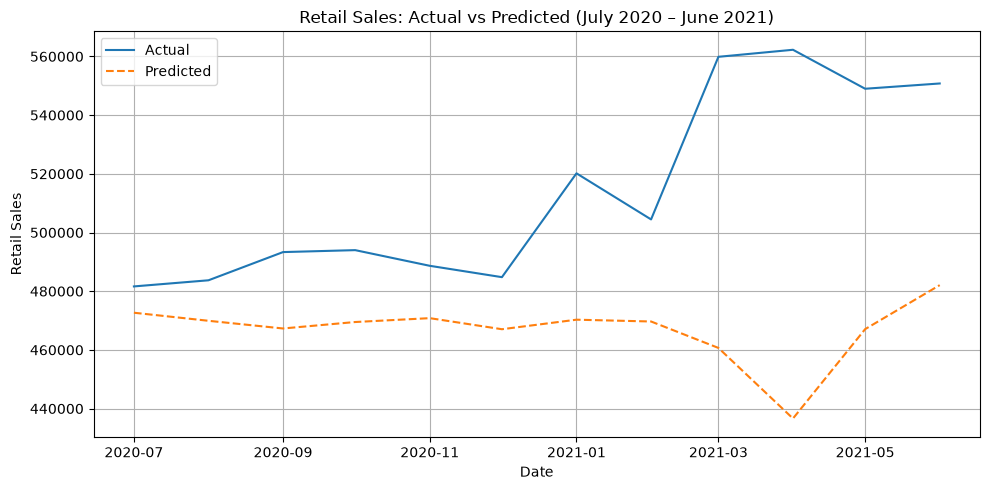

Saved: figures/actual_vs_predicted_retail_sales.png


In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    test,
    label="Actual"
)

plt.plot(
    forecast,
    label="Predicted",
    linestyle="--"
)

plt.title("Retail Sales: Actual vs Predicted (July 2020 – June 2021)")
plt.xlabel("Date")
plt.ylabel("Retail Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()

save_path = FIGURES_DIR / "actual_vs_predicted_retail_sales.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figures/actual_vs_predicted_retail_sales.png")


### Interpretation — Actual vs. Predicted Sales

The forecast is **below the actual value in all 12 test months**, indicating a consistent underestimation over July 2020–June 2021. In **July 2020**, actual sales were **481,627**, compared with a forecast of **472,662.2**, a difference of approximately **8,965**. The gap becomes substantially larger in 2021 as actual sales rise faster than the forecast.

The **largest monthly shortfall occurs in April 2021**: actual sales were **562,269**, while the model predicted **436,617.4**, an underestimation of approximately **125,652** (about **22.3%** of that month's actual value). In **June 2021**, the model still predicted **482,060.2** against actual sales of **550,782**.

The visual comparison therefore shows that the SARIMA model did not keep pace with the strong recovery in the test period. For retail planning, repeated underforecasting of this size could lead to overly conservative inventory, staffing, or budgeting assumptions. These findings describe performance on this particular 12-month test period, not every possible forecasting period.

## 9. Evaluate Forecast Accuracy

Root Mean Squared Error (**RMSE**) summarizes the typical scale of forecast errors while assigning greater weight to larger misses. The notebook computes RMSE from the 12 unrounded model forecasts and observed test values, then saves the result alongside the model's information criteria.

In [11]:
rmse = sqrt(
    np.mean(
        (forecast - test) ** 2
    )
)

print(
    "RMSE:",
    round(rmse, 2)
)


RMSE: 59819.07


In [12]:
model_metrics = pd.DataFrame({
    "Metric": [
        "AIC",
        "BIC",
        "HQIC",
        "RMSE"
    ],
    "Value": [
        fit.aic,
        fit.bic,
        fit.hqic,
        rmse
    ]
})

model_metrics.to_csv(
    RESULTS_DIR / "model_metrics.csv",
    index=False
)

display(
    model_metrics.style.format({
        "Value": "{:,.3f}"
    })
)

print("Saved: results/model_metrics.csv")


,Metric,Value
0,AIC,"6,430.359"
1,BIC,"6,449.122"
2,HQIC,"6,437.855"
3,RMSE,"59,819.071"


Saved: results/model_metrics.csv


### Interpretation — Forecast Accuracy

The held-out test-period **RMSE is 59,819.07**, expressed in the **same units as the source retail-sales figures**. This metric reflects the overall magnitude of the model's forecasting errors across the 12 months; because RMSE squares errors before averaging, large misses such as **April 2021** have a particularly strong influence.

The direction of the errors also matters: the forecasts are consistently **lower** than the observed sales. RMSE alone does not show that systematic bias, so the monthly forecast table and actual-versus-predicted chart provide essential complementary evidence.

Together, these results suggest that the fitted seasonal model provides a reproducible baseline but was **not sufficiently responsive to the rapid increase in sales during the 2021 test period**. A stronger evaluation could compare this model with a seasonal-naïve baseline and alternative specifications using the same chronological test window.

## 10. Saved Project Outputs

The notebook saves **two charts** in `figures/` and **two CSV files** in `results/`: monthly actual-versus-predicted values and model evaluation metrics. The output listing below confirms the filenames generated in the executed project environment.

In [13]:
print("Figures:")
for file in sorted(FIGURES_DIR.glob("*.png")):
    print(" -", f"figures/{file.name}")

print("\nResults:")
for file in sorted(RESULTS_DIR.glob("*.csv")):
    print(" -", f"results/{file.name}")


Figures:
 - figures/actual_vs_predicted_retail_sales.png
 - figures/us_monthly_retail_sales_trend.png

Results:
 - results/forecast_results.csv
 - results/model_metrics.csv


## Conclusion and Recommendations

This project demonstrates an end-to-end seasonal forecasting workflow: transforming a yearly-format source file into **354 monthly observations**, examining historical patterns, training a **SARIMA(1,1,1)(1,1,1,12)** model on **342 months**, and evaluating its forecasts on the final **12 months**.

### Key Findings

- **Historical pattern:** Retail sales generally increased over the observation period, with recurring within-year variation and pronounced changes around major economic disruptions.
- **Forecast direction:** The model underestimated actual retail sales in **every test month** from July 2020 through June 2021.
- **Largest shortfall:** In **April 2021**, actual sales were **562,269** versus **436,617.4** predicted, a difference of approximately **125,652** in the dataset's units.
- **Overall accuracy:** The 12-month test **RMSE was 59,819.07**. The results illustrate the difficulty of projecting a rapid rebound from earlier seasonal patterns.

### Business Implications and Recommendations

Forecasts can support retail budgeting, inventory planning, and staffing, but the persistent underestimation in this test period shows why model predictions should be reviewed alongside recent market conditions. Useful next steps include comparing SARIMA with a **seasonal-naïve baseline**, testing alternative model orders, using rolling-origin validation, and considering external economic indicators where appropriate.

### Limitations

This analysis evaluates **one SARIMA specification over one 12-month holdout period**; it does not establish that the model outperforms simpler forecasting methods. The historical series also includes unusual economic disruptions that can make past seasonal relationships less reliable for forecasting future changes.